### **We use the prtrained model for glacier mapping**


In [54]:
import torch
import numpy as np
import pandas as pd
import rasterio as rio
from glob import glob
from model import unet
from pyrsimg import imsShow
from processing import config
from pyrsimg import img2patch, metrics_segm
from model.mamba_seg.mamba_seg import MambaSeg  



In [55]:
## load trained model
path_trained_model = 'model/trained/unet_vmamba_pretrain_256_epoch_453_09515.pth'
# path_trained_model = 'model/trained/unet_vmamba_pretrain_1024_epoch_275_09601.pth'

model = MambaSeg(in_chans=6, 
                    num_classes=1, 
                    decoder_channels=32, 
                    dims=96,  
                    depths=(2, 2, 8, 2), 
                    backend='torch',
                    # backend='oflex', 
                    pretrained = True
                    )
model.load_state_dict(torch.load(path_trained_model, weights_only=True))
model.eval();  ##  



Loaded model/weights/vssm1_tiny_0230s_ckpt_epoch_264.pth; newly initialized output norms: ['outnorm0.weight', 'outnorm0.bias', 'outnorm1.weight', 'outnorm1.bias', 'outnorm2.weight', 'outnorm2.bias', 'outnorm3.weight', 'outnorm3.bias']


In [56]:
## data prepare: choose one scene for inference
print(len(config.paths_val_scene))
# id = np.random.randint(0, len(paths_val_scene))
id = 33
path_scene = config.paths_val_scene[id]
path_truth = config.paths_val_truth[id]
print('scene path:', path_scene)


43
scene path: data/dset/val/scene/l8_scene_11.tif


In [57]:
with rio.open(path_truth) as truth_rio:
    truth_arr = truth_rio.read(1)  # (H,W)
    profile_truth = truth_rio.profile
with rio.open(path_scene) as scene_rio:
    scene_arr = scene_rio.read()
    scene_arr = scene_arr.transpose((1, 2, 0))  # (H,W,C)
scene_arr.shape


(1257, 1537, 6)

In [60]:
patch_size = 256
def model_infer(scene_arr, model):
    ### image to patches
    imgPat_obj = img2patch(img=scene_arr, patch_size=patch_size, edge_overlay = 50)
    patch_arr_list = imgPat_obj.toPatch()
    # channel first and numpy array to torch tensor
    patch_list = [torch.from_numpy(patch.transpose(2,0,1)).float() 
                                        for patch in patch_arr_list]  
    with torch.no_grad():  ## save 
        presult_list = [model(patch[np.newaxis, :]) for patch in patch_list]
        presult_list = [torch.sigmoid(patch) for patch in presult_list]
    ## channel last and torch tensor to numpy array
    presult_arr_list = [np.squeeze(patch.detach().numpy().transpose(0,2,3,1), axis = 0) 
                                    for patch in presult_list ]       
    ## patch to image
    gla_pred_prob = imgPat_obj.toImage(presult_arr_list)
    gla_pred_cla = np.where(gla_pred_prob>0.5, 1, 0) 
    gla_pred_cla = gla_pred_cla.squeeze().astype(np.uint8)  
    return gla_pred_prob, gla_pred_cla

wat_pred_prob, wat_pred_cla = model_infer(scene_arr=scene_arr, model=model) 



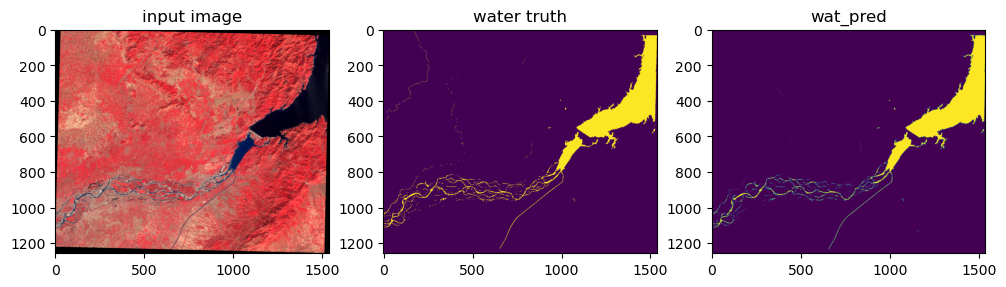

In [62]:
### show the results
imsShow([scene_arr, truth_arr, wat_pred_prob], 
        clip_list=[2, 2, 0], 
        color_bands_list = [[3,2,1], [0,0,0], [0,0,0]],
        img_name_list = ['input image', 'water truth', 'wat_pred'],
        figsize=(12, 3)); 


In [11]:
metrics_sg = metrics_segm(cla_map=wat_pred_cla, 
                          truth_map=truth_arr, 
                          class_labels=[0, 1],
                          mean_mode=True)
metrics_gla = {'oa': metrics_sg.oa,
               'dice_mean': metrics_sg.dice['labels_mean'],
               'miou': metrics_sg.iou['labels_mean']}
metrics_gla



{'oa': np.float64(0.9616435830493975),
 'dice_mean': np.float64(0.874905026908973),
 'miou': np.float64(0.7929969793649969)}

In [12]:
metrics_scenes, pred_maps = {}, {}
for path_scene, path_truth in zip(config.paths_val_scene, config.paths_val_truth):
    scene_id = path_scene.split('/')[-1].split('.')[0]
    print('scene id:', scene_id)
    with rio.open(path_truth) as truth_rio:
        truth_arr = truth_rio.read(1)  # (H,W)
        profile_truth = truth_rio.profile
    with rio.open(path_scene) as scene_rio:
        scene_arr = scene_rio.read().transpose((1, 2, 0))  # (H,W,C)
    wat_pred_cla = model_infer(scene_arr=scene_arr, model=model) 
    pred_maps[scene_id] = wat_pred_cla
    metrics_sg = metrics_segm(cla_map=wat_pred_cla, truth_map=truth_arr, 
                              class_labels=[0, 1], mean_mode=True)
    metrics = {'oa': metrics_sg.oa,
                   'dice_mean': metrics_sg.dice['labels_mean'],
                   'miou': metrics_sg.iou['labels_mean']}
    metrics_scenes[path_scene.split('/')[-1].split('.')[0]] = metrics


scene id: S2A_L2A_20190125_N0211_R034_S1
scene id: S2A_L2A_20190206_N0211_R067_S3
scene id: S2A_L2A_20190318_N0211_R061_S2
scene id: S2A_L2A_20190429_N0211_R096_S1
scene id: S2A_L2A_20190508_N0212_R078_S3
scene id: S2A_L2A_20190716_N0213_R063_S2
scene id: S2A_L2A_20190725_N0213_R054_S1
scene id: S2A_L2A_20190811_N0213_R013_S2
scene id: S2A_L2A_20190817_N0213_R089_S4
scene id: S2B_L2A_20181226_N0211_R102_S2
scene id: S2B_L2A_20190303_N0211_R065_S1
scene id: S2B_L2A_20190430_N0211_R035_S3
scene id: S2B_L2A_20190607_N0212_R012_S2
scene id: S2B_L2A_20190620_N0212_R053_S1
scene id: S2B_L2A_20190801_N0213_R084_S3
scene id: S2B_L2A_20190811_N0213_R079_S2
scene id: S2B_L2A_20190831_N0213_R082_S1
scene id: S2B_L2A_20190904_N0213_R132_S3
scene id: S2B_L2A_20191015_N0213_R007_S2
scene id: l5_scene_01
scene id: l5_scene_06
scene id: l5_scene_11
scene id: l5_scene_16
scene id: l5_scene_21
scene id: l5_scene_26
scene id: l7_scene_01
scene id: l7_scene_06
scene id: l7_scene_11
scene id: l7_scene_16
s

In [13]:
df_metrics_scenes = pd.DataFrame.from_dict(metrics_scenes, orient='index')
# df_metrics_scenes
df_metrics_scenes.mean()



oa           0.957527
dice_mean    0.925270
miou         0.876844
dtype: float64

### write out prediction map

In [14]:
### write the result to path
result_dir = config.dir_result + '/val_pred_1024to256/'
for scene_id, gla_pred_cla in pred_maps.items():
    path_save = result_dir + scene_id + '_pred.tif'   ## path to save result
    profile_truth = rio.open(config.dir_val_truth + '/' + scene_id + '_truth.tif').profile  # Use the profile from the first truth file
    with rio.open(path_save, 'w', **profile_truth) as dst:
        dst.write(gla_pred_cla, 1)   ## write to the first band    

